# DNA Sequence Classification Using Machine Learning

**Objective:** To classify DNA sequences into four categories: Bacteria, Human, Plant and Virus using different machine learning algorithms.

We use EDA, feature engineering, data preprocessing, model training and evaluation techniques to identify the best-performing classification model.

1. # 1. DATA LOADING: upload and read the dataset

In [1]:
import pandas as pd

df = pd.read_csv("dna_classification_dataset_New.csv")
df.head()

,Sample_ID,Sequence,GC_Content,AT_Content,Sequence_Length,Num_A,Num_T,Num_C,Num_G,kmer_3_freq,Mutation_Flag,Class_Label
0,S01802,TCCGCCACTCTGCCATCCAGCAAGCAGAGGGAAGACCATCCAGAGT...,57.0,43.0,100,23,20,29,28,0.7344,0,Plant
1,S01191,TGGTATTAGCAAATCGCTAAGGGCGGTTTTAAGTCTCTAATCTATT...,44.0,56.0,100,19,37,19,25,0.7031,0,Bacteria
2,S01818,GGGTAAGAGCCTTCGAAACCGCAAGCGCGCAACCCAAGAGGAGGCC...,56.0,44.0,100,30,14,27,29,0.7344,0,Plant
3,S00252,CCGAAACCTGTATTTTCATCGATTTATGAGCGAGGGTGGATCGGTC...,46.0,54.0,100,25,29,19,27,0.8594,0,Human
4,S02506,GTATGCCTCTCGCGTTAAACCTGTAGTGGGAGCGCGCTTCTCATTA...,53.0,47.0,100,19,28,26,27,0.7500,0,Virus


# 2. DATA OVERVIEW: number of rows, columns and column names

In [2]:
print("=" * 40)
print("DATASET OVERVIEW")
print("=" * 40)
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")
print(f"Columns list: {list(df.columns)}")

DATASET OVERVIEW
Rows    : 3000
Columns : 12
Columns list: ['Sample_ID', 'Sequence', 'GC_Content', 'AT_Content', 'Sequence_Length', 'Num_A', 'Num_T', 'Num_C', 'Num_G', 'kmer_3_freq', 'Mutation_Flag', 'Class_Label']


 Data quality check: missing values and duplicates

In [3]:
print("=" * 40)
print("DATA QUALITY")
print("=" * 40)
print(f"Missing values      : {df.isnull().sum().sum()}")
print(f"Duplicate rows      : {df.duplicated().sum()}")
print(f"Duplicate sequences : {df['Sequence'].duplicated().sum()}")

DATA QUALITY
Missing values      : 0
Duplicate rows      : 0
Duplicate sequences : 0


Class distribution: check if classes are balanced

In [4]:
counts = df['Class_Label'].value_counts().rename('Count').to_frame()
counts['Percent'] = (counts['Count'] / len(df) * 100).round(1)
counts

,Count,Percent
Class_Label,,
Plant,750,25.0
Bacteria,750,25.0
Human,750,25.0
Virus,750,25.0


Unique values and data types: find useless columns

In [5]:
pd.DataFrame({'Unique values': df.nunique(), 'Data type': df.dtypes})

,Unique values,Data type
Sample_ID,3000,object
Sequence,3000,object
GC_Content,42,float64
AT_Content,42,float64
Sequence_Length,1,int64
Num_A,34,int64
Num_T,35,int64
Num_C,37,int64
Num_G,32,int64
kmer_3_freq,22,float64


Statistical summary of numeric columns

In [6]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
GC_Content,3000.0,50.25,5.95,25.00,47.0,51.00,54.00,70.00
AT_Content,3000.0,49.75,5.95,30.00,46.0,49.00,53.00,75.00
Sequence_Length,3000.0,100.00,0.00,100.00,100.0,100.00,100.00,100.00
Num_A,3000.0,25.14,5.07,7.00,22.0,25.00,29.00,42.00
Num_T,3000.0,24.61,5.30,8.00,21.0,24.00,28.00,43.00
Num_C,3000.0,24.54,4.81,7.00,21.0,24.00,28.00,46.00
Num_G,3000.0,25.71,4.68,11.00,23.0,26.00,29.00,43.00
kmer_3_freq,3000.0,0.73,0.05,0.56,0.7,0.73,0.77,0.89
Mutation_Flag,3000.0,0.00,0.00,0.00,0.0,0.00,0.00,0.00


# 3. EDA (Exploratory Data Analysis): imports for plotting

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

EDA 1: Class balance plot

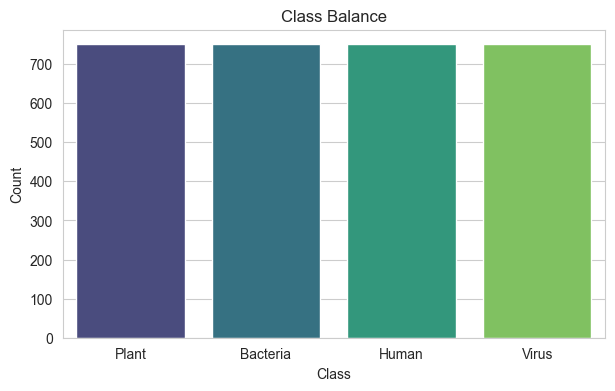

In [8]:
plt.figure(figsize=(7, 4))
sns.countplot(x='Class_Label', hue='Class_Label', data=df, palette='viridis', legend=False)
plt.title('Class Balance')
plt.xlabel('Class'); plt.ylabel('Count')
plt.show()

EDA 2: GC content per class (boxplot)

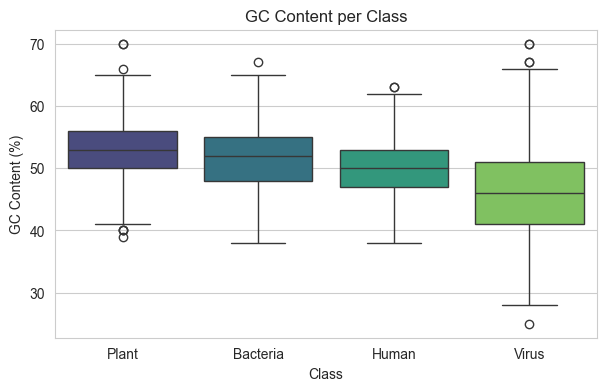

In [9]:
plt.figure(figsize=(7, 4))
sns.boxplot(x='Class_Label', y='GC_Content', hue='Class_Label', data=df, palette='viridis', legend=False)
plt.title('GC Content per Class')
plt.xlabel('Class'); plt.ylabel('GC Content (%)')
plt.show()

 EDA 3: kmer_3_freq per class (boxplot)

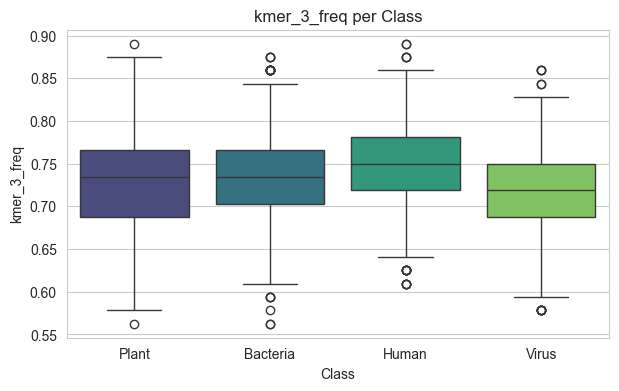

In [10]:
plt.figure(figsize=(7, 4))
sns.boxplot(x='Class_Label', y='kmer_3_freq', hue='Class_Label', data=df, palette='viridis', legend=False)
plt.title('kmer_3_freq per Class')
plt.xlabel('Class'); plt.ylabel('kmer_3_freq')
plt.show()

EDA 4: GC content distribution by class

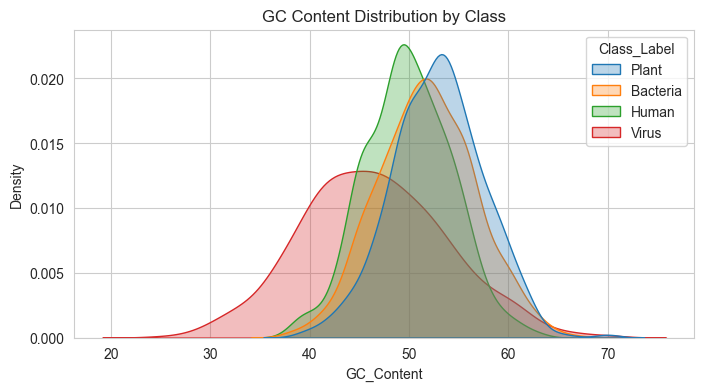

In [11]:
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df, x='GC_Content', hue='Class_Label', fill=True, alpha=0.3)
plt.title('GC Content Distribution by Class')
plt.show()

EDA 5: Correlation heatmap of numeric features

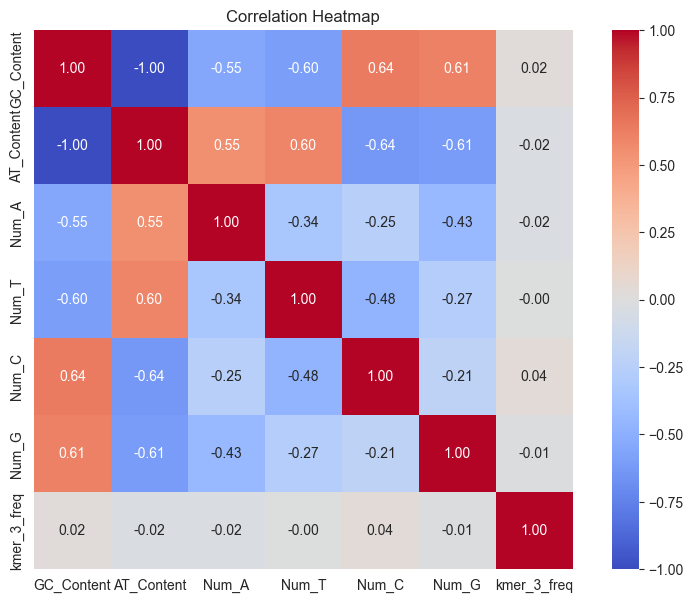

In [12]:
corr = df.drop(columns=['Sequence_Length', 'Mutation_Flag']).select_dtypes('number').corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Heatmap')
plt.show()

# 4. FEATURE ENGINEERING: function to compute k-mer frequencies

In [13]:
import numpy as np
import itertools

def kmer_freq(seqs, k):
    kmers = [''.join(p) for p in itertools.product('ACGT', repeat=k)]
    out = []
    for s in seqs:
        n = len(s) - k + 1
        counts = dict.fromkeys(kmers, 0)
        for i in range(n):
            counts[s[i:i+k]] += 1
        out.append([counts[m] / n for m in kmers])
    return pd.DataFrame(out, columns=[f'{k}mer_{m}' for m in kmers])

Create 2-mer (16) and 3-mer (64) features

In [14]:
k2 = kmer_freq(df['Sequence'], 2)   # 16 features
k3 = kmer_freq(df['Sequence'], 3)   # 64 features
print("2-mer shape:", k2.shape)
print("3-mer shape:", k3.shape)
k2.head()

2-mer shape: (3000, 16)
3-mer shape: (3000, 64)


,2mer_AA,2mer_AC,2mer_AG,2mer_AT,2mer_CA,2mer_CC,2mer_CG,2mer_CT,2mer_GA,2mer_GC,2mer_GG,2mer_GT,2mer_TA,2mer_TC,2mer_TG,2mer_TT
0,0.030303,0.020202,0.111111,0.070707,0.111111,0.080808,0.040404,0.060606,0.070707,0.111111,0.060606,0.040404,0.020202,0.080808,0.070707,0.020202
1,0.070707,0.020202,0.040404,0.050505,0.050505,0.010101,0.070707,0.060606,0.010101,0.070707,0.090909,0.080808,0.060606,0.090909,0.050505,0.171717
2,0.080808,0.050505,0.101010,0.060606,0.070707,0.101010,0.080808,0.020202,0.090909,0.090909,0.060606,0.050505,0.060606,0.030303,0.040404,0.010101
3,0.060606,0.030303,0.080808,0.080808,0.040404,0.050505,0.060606,0.040404,0.070707,0.050505,0.060606,0.090909,0.080808,0.050505,0.070707,0.080808
4,0.060606,0.020202,0.060606,0.040404,0.040404,0.040404,0.121212,0.060606,0.020202,0.121212,0.040404,0.090909,0.070707,0.080808,0.040404,0.090909


Build final feature matrix X (82 features) and target y

In [15]:
base = df[['GC_Content', 'kmer_3_freq']].reset_index(drop=True)
X = pd.concat([base, k2, k3], axis=1)
y = df['Class_Label']

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
X.head()

Feature matrix shape: (3000, 82)
Target shape: (3000,)


,GC_Content,kmer_3_freq,2mer_AA,2mer_AC,2mer_AG,2mer_AT,2mer_CA,2mer_CC,2mer_CG,2mer_CT,...,3mer_TCG,3mer_TCT,3mer_TGA,3mer_TGC,3mer_TGG,3mer_TGT,3mer_TTA,3mer_TTC,3mer_TTG,3mer_TTT
0,57.0,0.7344,0.030303,0.020202,0.111111,0.070707,0.111111,0.080808,0.040404,0.060606,...,0.000000,0.020408,0.020408,0.030612,0.000000,0.020408,0.000000,0.000000,0.010204,0.000000
1,44.0,0.7031,0.070707,0.020202,0.040404,0.050505,0.050505,0.010101,0.070707,0.060606,...,0.030612,0.040816,0.000000,0.010204,0.020408,0.020408,0.020408,0.030612,0.040816,0.081633
2,56.0,0.7344,0.080808,0.050505,0.101010,0.060606,0.070707,0.101010,0.080808,0.020202,...,0.020408,0.000000,0.010204,0.020408,0.000000,0.010204,0.000000,0.010204,0.000000,0.000000
3,46.0,0.8594,0.060606,0.030303,0.080808,0.080808,0.040404,0.050505,0.060606,0.040404,...,0.020408,0.010204,0.010204,0.010204,0.030612,0.020408,0.010204,0.010204,0.020408,0.030612
4,53.0,0.7500,0.060606,0.020202,0.060606,0.040404,0.040404,0.040404,0.121212,0.060606,...,0.020408,0.030612,0.010204,0.010204,0.010204,0.010204,0.051020,0.040816,0.000000,0.000000


# 5. PREPROCESSING: encode class names to numbers

In [16]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_enc = le.fit_transform(y)
print("Class mapping:", dict(zip(le.classes_, range(len(le.classes_)))))

Class mapping: {'Bacteria': 0, 'Human': 1, 'Plant': 2, 'Virus': 3}


Train-test split (80/20, stratified)

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=42)

print("Train:", X_train.shape)
print("Test :", X_test.shape)
print("Train class counts:", np.bincount(y_train))
print("Test class counts :", np.bincount(y_test))

Train: (2400, 82)
Test : (600, 82)
Train class counts: [600 600 600 600]
Test class counts : [150 150 150 150]


Normalization: scale features to range 0 to 1

In [18]:
from sklearn.preprocessing import MinMaxScaler

mm = MinMaxScaler()
X_train_mm = mm.fit_transform(X_train)
X_test_mm = mm.transform(X_test)

print("Min after normalization:", X_train_mm.min().round(2))
print("Max after normalization:", X_train_mm.max().round(2))

Min after normalization: 0.0
Max after normalization: 1.0


Standardization: mean 0, standard deviation 1

In [19]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
X_train_ss = ss.fit_transform(X_train)
X_test_ss = ss.transform(X_test)

print("Mean after standardization:", X_train_ss.mean().round(3))
print("Std after standardization :", X_train_ss.std().round(3))

Mean after standardization: -0.0
Std after standardization : 1.0


Effect of scaling on SVM and KNN

In [20]:
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

for name, Xtr, Xte in [('No scaling',             X_train,    X_test),
                       ('Normalization (MinMax)', X_train_mm, X_test_mm),
                       ('Standardization',        X_train_ss, X_test_ss)]:
    for mname, m in [('SVM', SVC()), ('KNN', KNeighborsClassifier())]:
        m.fit(Xtr, y_train)
        acc = accuracy_score(y_test, m.predict(Xte)) * 100
        print(f"{mname:4s} | {name:24s}: {acc:.2f}%")

SVM  | No scaling              : 41.33%
KNN  | No scaling              : 94.00%
SVM  | Normalization (MinMax)  : 99.00%
KNN  | Normalization (MinMax)  : 98.50%
SVM  | Standardization         : 99.00%
KNN  | Standardization         : 98.50%


# 6. MODEL TRAINING: helper function to store accuracy

In [21]:
from sklearn.metrics import accuracy_score

results = {}   # every model's accuracy gets stored here

def report(name, model, Xtr, Xte):
    train_acc = accuracy_score(y_train, model.predict(Xtr)) * 100
    test_acc = accuracy_score(y_test, model.predict(Xte)) * 100
    results[name] = [round(train_acc, 2), round(test_acc, 2)]
    print(f"{name}")
    print(f"  Train Accuracy: {train_acc:.2f}%")
    print(f"  Test Accuracy : {test_acc:.2f}%")

Model: Decision Tree

In [22]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
report('Decision Tree', dt, X_train, X_test)

Decision Tree
  Train Accuracy: 100.00%
  Test Accuracy : 88.83%


Model: Random Forest

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
report('Random Forest', rf, X_train, X_test)

Random Forest
  Train Accuracy: 100.00%
  Test Accuracy : 98.83%


Model: AdaBoost

In [24]:
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(random_state=42)
ada.fit(X_train, y_train)
report('AdaBoost', ada, X_train, X_test)

AdaBoost
  Train Accuracy: 95.83%
  Test Accuracy : 92.00%


Model: XGBoost

In [28]:
!pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)



[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
from xgboost import XGBClassifier

xgb = XGBClassifier(eval_metric='mlogloss', random_state=42)
xgb.fit(X_train, y_train)
report('XGBoost', xgb, X_train, X_test)

XGBoost
  Train Accuracy: 100.00%
  Test Accuracy : 99.00%


Model: Naive Bayes

In [30]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_ss, y_train)
report('Naive Bayes', nb, X_train_ss, X_test_ss)

Naive Bayes
  Train Accuracy: 98.42%
  Test Accuracy : 97.83%


Model: Logistics Regression

In [31]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=2000)
lr.fit(X_train_ss, y_train)
report('Logistic Reg.', lr, X_train_ss, X_test_ss)

Logistic Reg.
  Train Accuracy: 100.00%
  Test Accuracy : 99.33%


Model: KNN

In [32]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(X_train_ss, y_train)
report('KNN', knn, X_train_ss, X_test_ss)

KNN
  Train Accuracy: 99.29%
  Test Accuracy : 98.50%


Model: SVM

In [33]:
from sklearn.svm import SVC

svm = SVC()
svm.fit(X_train_ss, y_train)
report('SVM', svm, X_train_ss, X_test_ss)

SVM
  Train Accuracy: 100.00%
  Test Accuracy : 99.00%


Model comparison table (train vs test accuracy)

In [34]:
results_df = pd.DataFrame(results, index=['Train Acc (%)', 'Test Acc (%)']).T
results_df = results_df.sort_values('Test Acc (%)', ascending=False)
results_df

,Train Acc (%),Test Acc (%)
Logistic Reg.,100.00,99.33
XGBoost,100.00,99.00
SVM,100.00,99.00
Random Forest,100.00,98.83
KNN,99.29,98.50
Naive Bayes,98.42,97.83
AdaBoost,95.83,92.00
Decision Tree,100.00,88.83


Accuracy, Precision, Recall and F1-score of all models

In [35]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store evaluation results of all 8 models
models = {
    'Decision Tree': (dt, X_test),
    'Random Forest': (rf, X_test),
    'AdaBoost': (ada, X_test),
    'XGBoost': (xgb, X_test),
    'Naive Bayes': (nb, X_test_ss),
    'Logistic Regression': (lr, X_test_ss),
    'KNN': (knn, X_test_ss),
    'SVM': (svm, X_test_ss)
}

metric_results = []

for name, (model, test_data) in models.items():

    y_pred_model = model.predict(test_data)

    metric_results.append({
        'Model': name,
        'Accuracy (%)': round(
            accuracy_score(y_test, y_pred_model) * 100, 2
        ),
        'Precision (%)': round(
            precision_score(
                y_test, y_pred_model, average='macro'
            ) * 100, 2
        ),
        'Recall (%)': round(
            recall_score(
                y_test, y_pred_model, average='macro'
            ) * 100, 2
        ),
        'F1 Score (%)': round(
            f1_score(
                y_test, y_pred_model, average='macro'
            ) * 100, 2
        )
    })

metrics_df = pd.DataFrame(metric_results)

metrics_df = metrics_df.sort_values(
    by='F1 Score (%)',
    ascending=False
)

print("MODEL PERFORMANCE COMPARISON")
display(metrics_df)


MODEL PERFORMANCE COMPARISON


,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
5,Logistic Regression,99.33,99.34,99.33,99.33
3,XGBoost,99.00,99.01,99.00,99.00
7,SVM,99.00,99.00,99.00,99.00
1,Random Forest,98.83,98.83,98.83,98.83
6,KNN,98.50,98.50,98.50,98.50
4,Naive Bayes,97.83,97.84,97.83,97.84
2,AdaBoost,92.00,92.37,92.00,92.06
0,Decision Tree,88.83,88.87,88.83,88.82


Bar chart: test accuracy of all models

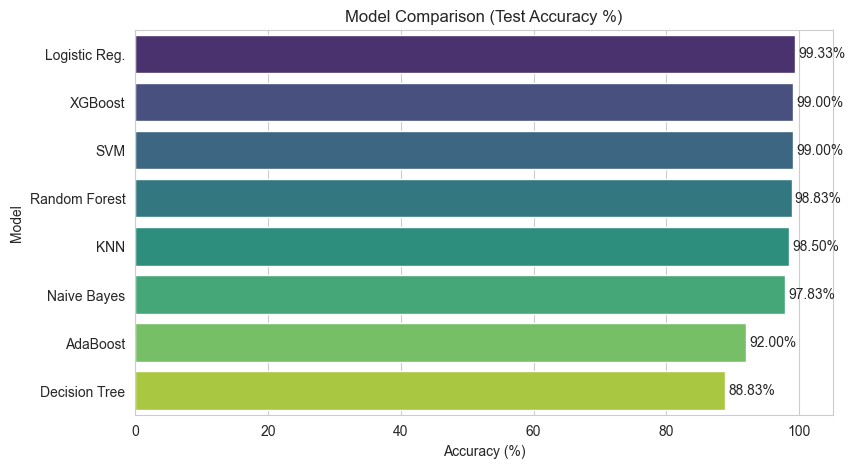

In [36]:
plot_df = results_df.reset_index().rename(columns={'index': 'Model'})

plt.figure(figsize=(9, 5))
sns.barplot(x='Test Acc (%)', y='Model', hue='Model', data=plot_df, palette='viridis', legend=False)
plt.title('Model Comparison (Test Accuracy %)')
plt.xlim(0, 105)
for i, v in enumerate(plot_df['Test Acc (%)']):
    plt.text(v + 0.5, i, f'{v:.2f}%', va='center')
plt.xlabel('Accuracy (%)')
plt.show()

# 7. CROSS-VALIDATION: 5-fold, checks how stable each model is

In [37]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

def cv_report(name, model, scaled=False):
    est = make_pipeline(StandardScaler(), clone(model)) if scaled else clone(model)
    scores = cross_val_score(est, X_train, y_train, cv=skf, scoring='accuracy') * 100
    cv_results[name] = [round(scores.mean(), 2), round(scores.std(), 2)]
    print(f"{name}")
    print(f"  Fold scores : {np.round(scores, 2)}")
    print(f"  Mean ± Std  : {scores.mean():.2f}% ± {scores.std():.2f}%")

CV: Decision Tree

In [38]:
cv_report('Decision Tree', dt)

Decision Tree
  Fold scores : [92.71 87.71 88.96 90.62 87.5 ]
  Mean ± Std  : 89.50% ± 1.95%


CV: Random Forest

In [39]:
cv_report('Random Forest', rf)

Random Forest
  Fold scores : [98.96 98.96 99.38 98.96 97.5 ]
  Mean ± Std  : 98.75% ± 0.65%


CV: AdaBoost

In [40]:
cv_report('AdaBoost', ada)

AdaBoost
  Fold scores : [95.83 93.33 96.88 95.62 93.33]
  Mean ± Std  : 95.00% ± 1.43%


CV: XGBoost

In [41]:
cv_report('XGBoost', xgb)

XGBoost
  Fold scores : [99.38 98.96 98.75 98.96 97.92]
  Mean ± Std  : 98.79% ± 0.48%


CV: Naive Bayes

In [42]:
cv_report('Naive Bayes', nb, scaled=True)

Naive Bayes
  Fold scores : [98.75 98.33 99.38 98.33 96.88]
  Mean ± Std  : 98.33% ± 0.82%


CV : Logistic Regression

In [43]:
cv_report('Logistic Reg.', lr, scaled=True)

Logistic Reg.
  Fold scores : [99.17 99.17 99.58 98.96 98.54]
  Mean ± Std  : 99.08% ± 0.34%


CV: KNN

In [44]:
cv_report('KNN', knn, scaled=True)

KNN
  Fold scores : [99.17 98.12 99.58 98.75 98.12]
  Mean ± Std  : 98.75% ± 0.57%


CV: SVM

In [45]:
cv_report('SVM', svm, scaled=True)

SVM
  Fold scores : [99.38 99.38 99.79 99.17 98.54]
  Mean ± Std  : 99.25% ± 0.41%


CV comparison table

In [46]:
cv_df = pd.DataFrame(cv_results, index=['CV Mean (%)', 'CV Std (%)']).T
cv_df = cv_df.sort_values('CV Mean (%)', ascending=False)
cv_df

,CV Mean (%),CV Std (%)
SVM,99.25,0.41
Logistic Reg.,99.08,0.34
XGBoost,98.79,0.48
Random Forest,98.75,0.65
KNN,98.75,0.57
Naive Bayes,98.33,0.82
AdaBoost,95.00,1.43
Decision Tree,89.50,1.95


CV plot: mean accuracy with standard deviation

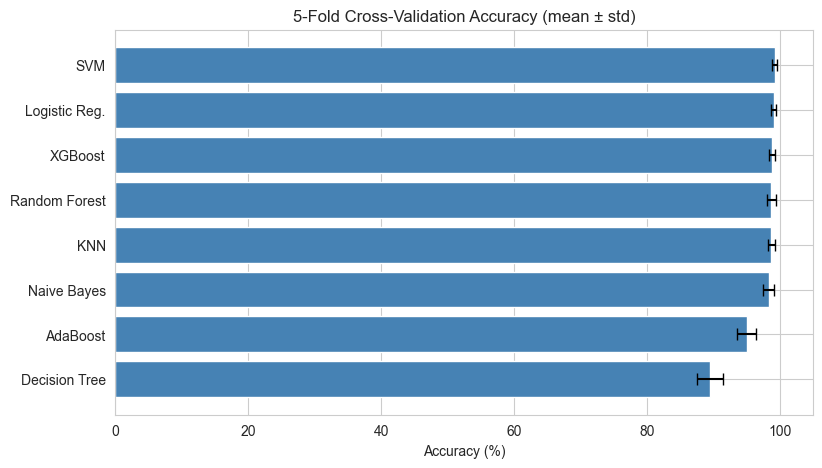

In [47]:
plt.figure(figsize=(9, 5))
plt.barh(cv_df.index, cv_df['CV Mean (%)'], xerr=cv_df['CV Std (%)'],
         color='steelblue', capsize=4)
plt.gca().invert_yaxis()
plt.xlim(0, 105)
plt.title('5-Fold Cross-Validation Accuracy (mean ± std)')
plt.xlabel('Accuracy (%)')
plt.show()

# 8. OVERFITTING CHECK: gap between train and test accuracy

In [48]:
overfit_df = pd.DataFrame(results, index=['Train Acc (%)', 'Test Acc (%)']).T
overfit_df['Gap (%)'] = (overfit_df['Train Acc (%)'] - overfit_df['Test Acc (%)']).round(2)
overfit_df.sort_values('Gap (%)', ascending=False)

,Train Acc (%),Test Acc (%),Gap (%)
Decision Tree,100.00,88.83,11.17
AdaBoost,95.83,92.00,3.83
Random Forest,100.00,98.83,1.17
XGBoost,100.00,99.00,1.00
SVM,100.00,99.00,1.00
KNN,99.29,98.50,0.79
Logistic Reg.,100.00,99.33,0.67
Naive Bayes,98.42,97.83,0.59


Plot: train vs test accuracy

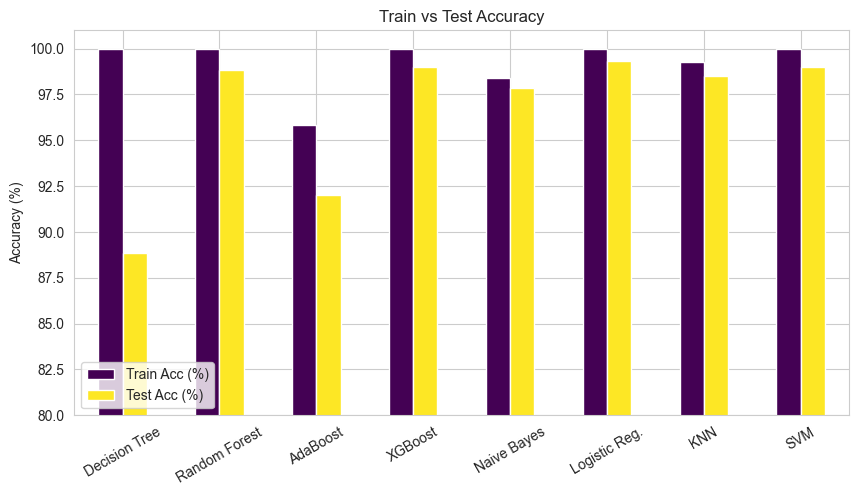

In [49]:
overfit_df[['Train Acc (%)', 'Test Acc (%)']].plot(kind='bar', figsize=(10, 5), colormap='viridis')
plt.title('Train vs Test Accuracy')
plt.ylabel('Accuracy (%)')
plt.ylim(80, 101)
plt.xticks(rotation=30)
plt.legend(loc='lower left')
plt.show()

# 9. HYPERPARAMETER TUNING: SVM using GridSearchCV

In [50]:
from sklearn.model_selection import GridSearchCV

svm_params = {'C': [0.1, 1, 10, 100],
              'gamma': ['scale', 0.01, 0.001],
              'kernel': ['rbf', 'linear']}

svm_grid = GridSearchCV(SVC(), svm_params, cv=skf, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train_ss, y_train)

print("Best parameters:", svm_grid.best_params_)
print(f"Best CV accuracy: {svm_grid.best_score_ * 100:.2f}%")

Best parameters: {'C': 1, 'gamma': 0.001, 'kernel': 'rbf'}
Best CV accuracy: 99.38%


Tuning: Logistic Regression

In [51]:
lr_params = {'C': [0.01, 0.1, 1, 10, 100]}

lr_grid = GridSearchCV(LogisticRegression(max_iter=2000), lr_params,
                       cv=skf, scoring='accuracy', n_jobs=-1)
lr_grid.fit(X_train_ss, y_train)

print("Best parameters:", lr_grid.best_params_)
print(f"Best CV accuracy: {lr_grid.best_score_ * 100:.2f}%")

Best parameters: {'C': 0.01}
Best CV accuracy: 99.17%


Tuning: XGBoost

In [52]:
xgb_params = {'n_estimators': [100, 200],
              'max_depth': [3, 5],
              'learning_rate': [0.05, 0.1, 0.2]}

xgb_grid = GridSearchCV(XGBClassifier(eval_metric='mlogloss', random_state=42),
                        xgb_params, cv=skf, scoring='accuracy', n_jobs=-1)
xgb_grid.fit(X_train, y_train)

print("Best parameters:", xgb_grid.best_params_)
print(f"Best CV accuracy: {xgb_grid.best_score_ * 100:.2f}%")

Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Best CV accuracy: 99.17%


 Default vs tuned CV accuracy

In [53]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def cv_mean(est, scaled):
    est = make_pipeline(StandardScaler(), est) if scaled else est
    return round(cross_val_score(est, X_train, y_train, cv=skf, scoring='accuracy').mean() * 100, 2)

tuned_df = pd.DataFrame({
    'Default CV (%)': [cv_mean(SVC(), True),
                       cv_mean(XGBClassifier(eval_metric='mlogloss', random_state=42), False),
                       cv_mean(LogisticRegression(max_iter=2000), True)],
    'Tuned CV (%)'  : [round(svm_grid.best_score_ * 100, 2),
                       round(xgb_grid.best_score_ * 100, 2),
                       round(lr_grid.best_score_ * 100, 2)]
}, index=['SVM', 'XGBoost', 'Logistic Reg.'])

tuned_df['Improvement (%)'] = (tuned_df['Tuned CV (%)'] - tuned_df['Default CV (%)']).round(2)
tuned_df.sort_values('Tuned CV (%)', ascending=False)

,Default CV (%),Tuned CV (%),Improvement (%)
SVM,99.25,99.38,0.13
XGBoost,98.79,99.17,0.38
Logistic Reg.,99.08,99.17,0.09


Tuning: AdaBoost

In [54]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

ada_params = {'n_estimators': [50, 200, 400],
              'learning_rate': [0.1, 0.5, 1.0]}

ada_grid = GridSearchCV(AdaBoostClassifier(random_state=42), ada_params,
                        cv=skf, scoring='accuracy', n_jobs=-1)
ada_grid.fit(X_train, y_train)

print("Best parameters:", ada_grid.best_params_)
print(f"Best CV accuracy : {ada_grid.best_score_ * 100:.2f}%")
print(f"Test accuracy    : {accuracy_score(y_test, ada_grid.best_estimator_.predict(X_test)) * 100:.2f}%")

Best parameters: {'learning_rate': 1.0, 'n_estimators': 400}
Best CV accuracy : 98.33%
Test accuracy    : 97.50%


# 10. FINAL MODEL EVALUATION: tuned SVM test accuracy

In [55]:
best_svm = svm_grid.best_estimator_
y_pred = best_svm.predict(X_test_ss)

print("Best parameters:", svm_grid.best_params_)
print(f"Final Test Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")

Best parameters: {'C': 1, 'gamma': 0.001, 'kernel': 'rbf'}
Final Test Accuracy: 98.83%


Precision, Recall and F1-score for each class

In [56]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=le.classes_, digits=4))

              precision    recall  f1-score   support

    Bacteria     0.9933    0.9933    0.9933       150
       Human     0.9737    0.9867    0.9801       150
       Plant     0.9867    0.9867    0.9867       150
       Virus     1.0000    0.9867    0.9933       150

    accuracy                         0.9883       600
   macro avg     0.9884    0.9883    0.9884       600
weighted avg     0.9884    0.9883    0.9884       600



 Confusion matrix: which classes get mixed up

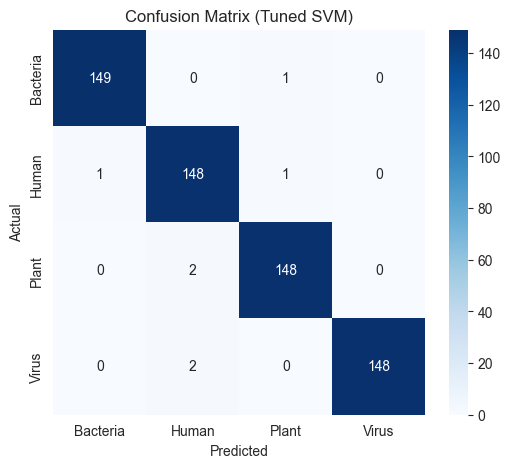

In [57]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Confusion Matrix (Tuned SVM)')
plt.show()

ROC curves and AUC (one-vs-rest)

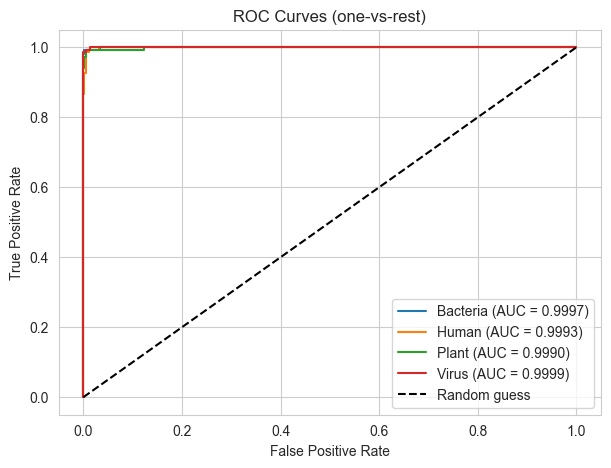

Average AUC: 0.9995


In [58]:
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import label_binarize

y_bin = label_binarize(y_test, classes=[0, 1, 2, 3])
scores = best_svm.decision_function(X_test_ss)

plt.figure(figsize=(7, 5))
aucs = []
for i, cls in enumerate(le.classes_):
    fpr, tpr, _ = roc_curve(y_bin[:, i], scores[:, i])
    auc = roc_auc_score(y_bin[:, i], scores[:, i])
    aucs.append(auc)
    plt.plot(fpr, tpr, label=f'{cls} (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves (one-vs-rest)')
plt.legend(loc='lower right')
plt.show()

print(f"Average AUC: {np.mean(aucs):.4f}")

Test accuracy of all tuned models

In [59]:
final = {
    'SVM (tuned)'          : (svm_grid.best_estimator_, X_test_ss),
    'XGBoost (tuned)'      : (xgb_grid.best_estimator_, X_test),
    'Logistic Reg. (tuned)': (lr_grid.best_estimator_, X_test_ss),
    'AdaBoost (tuned)'     : (ada_grid.best_estimator_, X_test),
}

rows = []
for name, (m, Xte) in final.items():
    rows.append([name, round(accuracy_score(y_test, m.predict(Xte)) * 100, 2)])

pd.DataFrame(rows, columns=['Model', 'Test Acc (%)']).sort_values('Test Acc (%)', ascending=False)

,Model,Test Acc (%)
2,Logistic Reg. (tuned),99.00
0,SVM (tuned),98.83
1,XGBoost (tuned),98.50
3,AdaBoost (tuned),97.50


Learning curve: accuracy vs training set size

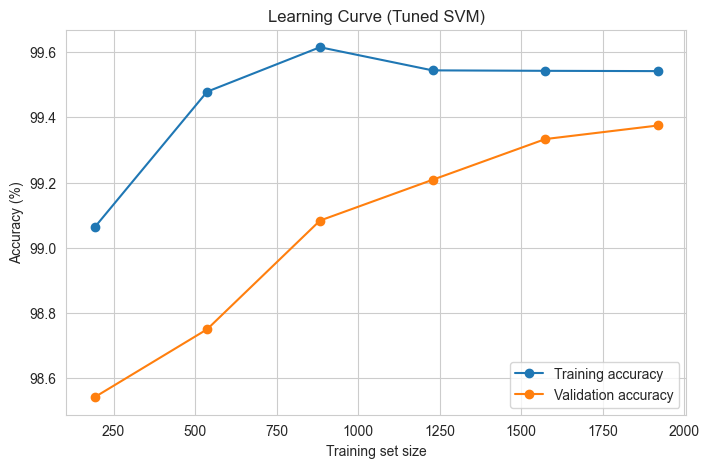

In [60]:
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(
    best_svm, X_train_ss, y_train, cv=skf,
    train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)

plt.figure(figsize=(8, 5))
plt.plot(sizes, train_sc.mean(axis=1) * 100, 'o-', label='Training accuracy')
plt.plot(sizes, val_sc.mean(axis=1) * 100, 'o-', label='Validation accuracy')
plt.xlabel('Training set size'); plt.ylabel('Accuracy (%)')
plt.title('Learning Curve (Tuned SVM)')
plt.legend(); plt.grid(True)
plt.show()

# 11. FEATURE IMPORTANCE: XGBoost

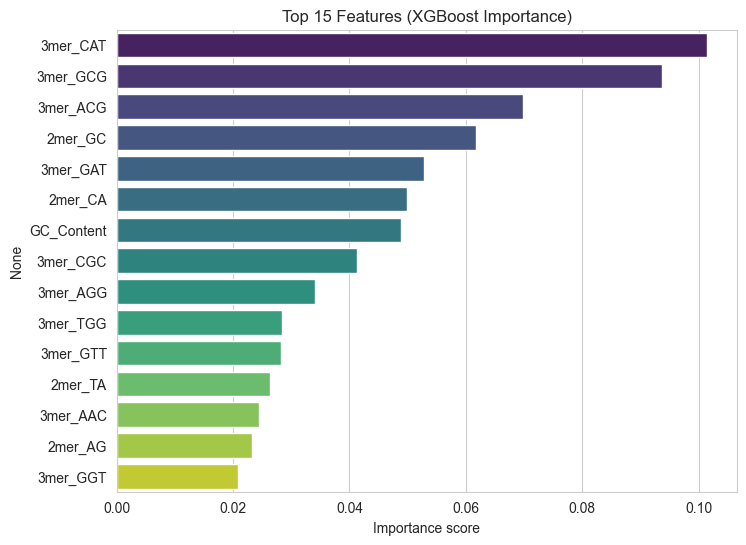

In [61]:
best_xgb = xgb_grid.best_estimator_
imp = pd.Series(best_xgb.feature_importances_, index=X.columns).sort_values(ascending=False)
top = imp.head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index, hue=top.index, palette='viridis', legend=False)
plt.title('Top 15 Features (XGBoost Importance)')
plt.xlabel('Importance score')
plt.show()

Feature importance: permutation importance for SVM

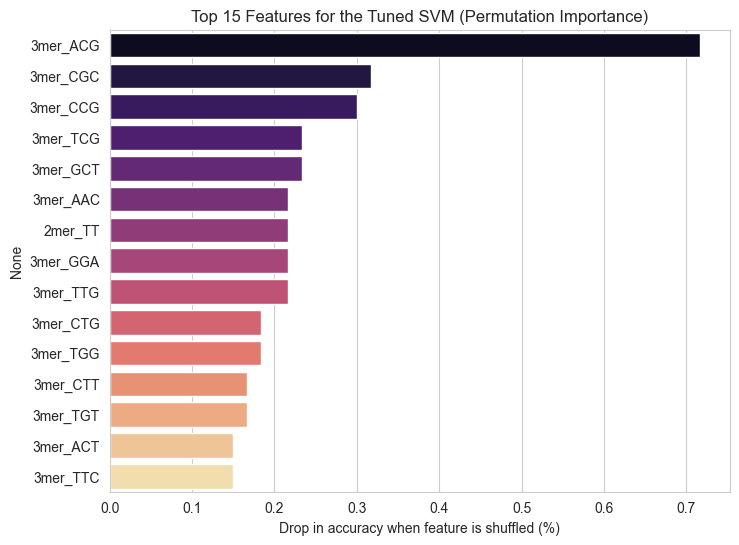

In [62]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_svm, X_test_ss, y_test,
                              n_repeats=10, random_state=42, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean * 100, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=perm_s.values, y=perm_s.index, hue=perm_s.index, palette='magma', legend=False)
plt.title('Top 15 Features for the Tuned SVM (Permutation Importance)')
plt.xlabel('Drop in accuracy when feature is shuffled (%)')
plt.show()

# 12. BEFORE vs AFTER k-mer features (SVM)

In [63]:
base_cols = ['GC_Content', 'kmer_3_freq']

ss_base = StandardScaler()
Xb_train = ss_base.fit_transform(X_train[base_cols])
Xb_test = ss_base.transform(X_test[base_cols])

svm_base = SVC(**svm_grid.best_params_)
svm_base.fit(Xb_train, y_train)
acc_before = accuracy_score(y_test, svm_base.predict(Xb_test)) * 100
acc_after = accuracy_score(y_test, y_pred) * 100

print(f"SVM before k-mer features (2 features) : {acc_before:.2f}%")
print(f"SVM after k-mer features (82 features) : {acc_after:.2f}%")
print(f"Improvement                            : {acc_after - acc_before:.2f}%")

SVM before k-mer features (2 features) : 38.50%
SVM after k-mer features (82 features) : 98.83%
Improvement                            : 60.33%


Plot: effect of k-mer feature engineering

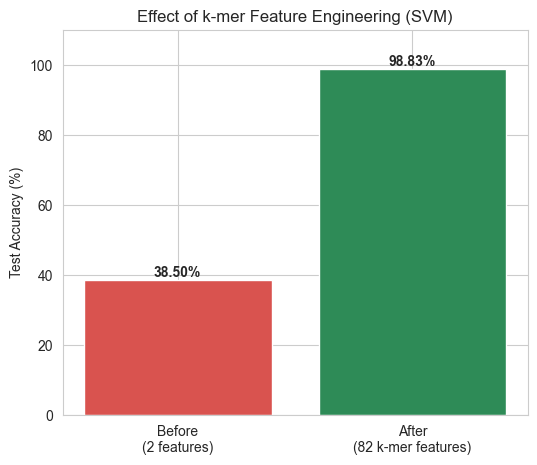

In [64]:
plt.figure(figsize=(6, 5))
bars = plt.bar(['Before\n(2 features)', 'After\n(82 k-mer features)'],
               [acc_before, acc_after], color=['#d9534f', '#2e8b57'])
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 1,
             f'{b.get_height():.2f}%', ha='center', fontweight='bold')
plt.ylim(0, 110)
plt.ylabel('Test Accuracy (%)')
plt.title('Effect of k-mer Feature Engineering (SVM)')
plt.show()

In [66]:

import joblib
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Model name: (model, scaling required, training data, testing data)
model_specs = {
    "Decision Tree": (dt, False, X_train, X_test),
    "Random Forest": (rf, False, X_train, X_test),
    "AdaBoost": (ada, False, X_train, X_test),
    "XGBoost": (xgb, False, X_train, X_test),
    "Naive Bayes": (nb, True, X_train_ss, X_test_ss),
    "Logistic Regression": (lr, True, X_train_ss, X_test_ss),
    "KNN": (knn, True, X_train_ss, X_test_ss),
    "SVM": (svm, True, X_train_ss, X_test_ss),

    "SVM (Tuned)": (
        svm_grid.best_estimator_, True,
        X_train_ss, X_test_ss
    ),
    "XGBoost (Tuned)": (
        xgb_grid.best_estimator_, False,
        X_train, X_test
    ),
    "Logistic Regression (Tuned)": (
        lr_grid.best_estimator_, True,
        X_train_ss, X_test_ss
    ),
    "AdaBoost (Tuned)": (
        ada_grid.best_estimator_, False,
        X_train, X_test
    )
}

models_for_dashboard = {}
metrics_for_dashboard = {}

for name, (model, scaled, train_data, test_data) in model_specs.items():

    train_predictions = model.predict(train_data)
    test_predictions = model.predict(test_data)

    models_for_dashboard[name] = {
        "estimator": model,
        "scaled": scaled
    }

    metrics_for_dashboard[name] = {
        "train_accuracy": round(
            accuracy_score(y_train, train_predictions) * 100, 2
        ),
        "test_accuracy": round(
            accuracy_score(y_test, test_predictions) * 100, 2
        ),
        "precision": round(
            precision_score(
                y_test, test_predictions, average="macro",
                zero_division=0
            ) * 100, 2
        ),
        "recall": round(
            recall_score(
                y_test, test_predictions, average="macro",
                zero_division=0
            ) * 100, 2
        ),
        "f1_score": round(
            f1_score(
                y_test, test_predictions, average="macro",
                zero_division=0
            ) * 100, 2
        ),
        "confusion_matrix": confusion_matrix(
            y_test,
            test_predictions,
            labels=np.arange(len(le.classes_))
        ).tolist()
    }

bundle = {
    "models": models_for_dashboard,
    "metrics": metrics_for_dashboard,
    "feature_columns": list(X.columns),
    "class_names": le.classes_.tolist(),
    "scaler": ss,
    "label_encoder": le
}

joblib.dump(bundle, "dashboard_bundle.joblib")

print("Models exported:", len(models_for_dashboard))
print("Class names:", le.classes_.tolist())
print("Dashboard bundle created successfully.")

print("Saved file: dashboard_bundle.joblib")

Models exported: 12
Class names: ['Bacteria', 'Human', 'Plant', 'Virus']
Dashboard bundle created successfully.
Saved file: dashboard_bundle.joblib


In [67]:

import joblib
import numpy as np
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize

# Convert encoded class labels into a binary matrix for multiclass ROC
classes = np.arange(len(le.classes_))
y_test_binary = label_binarize(y_test, classes=classes)

roc_curves = {}
roc_auc_scores = {}

for name, (model, scaled, train_data, test_data) in model_specs.items():

    # Get continuous prediction scores for ROC calculation
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(test_data)
    elif hasattr(model, "decision_function"):
        scores = model.decision_function(test_data)
    else:
        print("Skipping ROC for:", name)
        continue

    # Some models may expose classes in a different order
    model_classes = np.asarray(model.classes_)
    class_order = [list(model_classes).index(c) for c in classes]

    if scores.ndim == 2:
        scores = scores[:, class_order]

    model_curves = {}

    for i, class_name in enumerate(le.classes_):
        # ROC requires both positive and negative examples
        if len(np.unique(y_test_binary[:, i])) < 2:
            continue

        fpr, tpr, _ = roc_curve(
            y_test_binary[:, i],
            scores[:, i]
        )

        model_curves[str(class_name)] = {
            "fpr": fpr.tolist(),
            "tpr": tpr.tolist(),
            "auc": round(auc(fpr, tpr), 4)
        }

    # Macro one-vs-rest AUC score
    try:
        macro_auc = roc_auc_score(
            y_test,
            scores,
            labels=classes,
            multi_class="ovr",
            average="macro"
        )
    except ValueError:
        macro_auc = None

    roc_curves[name] = model_curves
    roc_auc_scores[name] = (
        round(float(macro_auc), 4)
        if macro_auc is not None
        else None
    )

# Add ROC data to the existing exported bundle
bundle = joblib.load("dashboard_bundle.joblib")
bundle["roc_curves"] = roc_curves
bundle["roc_auc_scores"] = roc_auc_scores

joblib.dump(bundle, "dashboard_bundle.joblib")

print("ROC curves exported for:", len(roc_curves), "models")
print("Macro AUC scores:", roc_auc_scores)

print("Updated dashboard_bundle.joblib saved.")

ROC curves exported for: 12 models
Macro AUC scores: {'Decision Tree': 0.9256, 'Random Forest': 0.9993, 'AdaBoost': 0.9877, 'XGBoost': 0.9998, 'Naive Bayes': 0.9993, 'Logistic Regression': 1.0, 'KNN': 0.9978, 'SVM': None, 'SVM (Tuned)': None, 'XGBoost (Tuned)': 0.9998, 'Logistic Regression (Tuned)': 0.9999, 'AdaBoost (Tuned)': 0.9966}
Updated dashboard_bundle.joblib saved.
